# 03 · Offline evaluation: what to select on

**Question.** A team without exploration traffic has only logged data, so it selects models with
self-normalised inverse propensity scoring (SNIPS) on held-out logged positives. How much better
does selection get with a small slice of uniform exposure, and how small can that slice be?

Every rule reads the same training trajectories (seed 42), so all rules compare the same fits and no
rule needs retraining. A rule picks a (configuration, step); regret is the test DCG@5 of the best point
for an oracle reading the test set, minus the test DCG@5 of the point the rule picks.

| Rule | Statistic | Meaning |
|---|---|---|
| A0 | Per-user DCG@5 divided by the user's number of held-out positives, no weights (rule A with unit weights) | Logged holdout, no correction |
| A | Per-user SNIPS DCG@5 on the same data | The paper's statistic |
| A+ | Pooled SNIPS DCG@5 | One normalisation over all positives, weights do not cancel |
| B | Per-user DCG@5 on `val_B` | Exploration bucket: 10% of the uniform-exposure users |
| B5a/b | The same on two disjoint halves of `val_B` | 5% buckets |
| B2.5a–d | The same on four disjoint quarters of `val_B` | 2.5% buckets |

A note on rule A: with one positive in a user's candidate list, per-user SNIPS cancels the weight and
equals the unweighted statistic. That holds for most validation users here, so this notebook calls rule A
"the paper's selection statistic" and does not claim it corrects the logged validation data.

In [1]:
import sys

sys.path[:0] = ["../src", "src"]  # from notebooks/ or from the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import AQUA, BLUE, GRAY, LABELS, MPL, ORANGE, RESULTS, RULES
from data import load, theta
from evaluate import ap, boot_idx, dcg, discount, load_scores, load_traj, orders, paired_ci, recall, score_vectors

plt.rcParams.update(MPL)
RESULTS.mkdir(exist_ok=True)
d, T, scores = load("yahoo"), load_traj("yahoo"), load_scores("yahoo")
G = T[T.phase == "grid"]
ORDER = ["A0", "A", "A+", "B", "B5a", "B5b", "B2.5a", "B2.5b", "B2.5c", "B2.5d"]

## 1. Selection regret

Two pools. "All models" lets the rule choose among every fit, including the choice of family. "Rel-MF only"
fixes the family (η = 0.5) and tunes M, λ̃ and the step.

In [2]:
def describe(r):
    if r.family in ("relmf", "relmf_eta025", "relmf_eta1", "nnpu", "balanced"):
        detail = f"η={r.eta:g}, M={r.M:g}, λ̃={r.lam_rel:g}"
    elif r.family == "wmf":
        detail = f"c′={r.c:g}, λ̃={r.lam_rel:g}"
    elif r.family == "scar":
        detail = f"c=1/{1 / r.c:.0f}, λ̃={r.lam_rel:g}"
    elif r.family == "popularity":
        detail = ""
    elif r.family == "bpr":
        detail = f"reg={r.lam_rel:g}"
    elif r.family == "ease":
        detail = f"λ={r.lam_rel:g}"
    else:
        detail = f"λ̃={r.lam_rel:g}"
    return f"{LABELS[r.family].split(' (')[0]}" + (f" ({detail})" if detail else "")


def regret_table(pool):
    oracle = pool.loc[pool.test_dcg5.idxmax()]
    rows = []
    for rule in ORDER + ["oracle"]:
        r = pool.loc[pool[RULES[rule]].idxmax()]
        rows.append({"rule": rule, "picks": describe(r), "step": int(r.step), "test DCG@5": r.test_dcg5,
                     "rare-credit": r.rare_credit5, "regret": oracle.test_dcg5 - r.test_dcg5})
    return pd.DataFrame(rows)


all_pool, relmf_pool = regret_table(G), regret_table(G[G.family == "relmf"])
print(all_pool.to_markdown(index=False, floatfmt=".4f"))
print(relmf_pool.to_markdown(index=False, floatfmt=".4f"))

FAMS = ["naive", "wmf", "scar", "relmf", "nnpu", "balanced", "bpr"]
rows = {}
for f in FAMS:
    tab = regret_table(G[G.family == f]).set_index("rule")
    rows[LABELS[f].split(" (")[0]] = {r: tab.loc[r, "regret"] for r in ("A0", "A", "A+", "B")} | {"best possible test DCG@5": tab.loc["oracle", "test DCG@5"]}
by_family = pd.DataFrame(rows).T
print(by_family.to_markdown(floatfmt=".4f"))

| rule   | picks                             |   step |   test DCG@5 |   rare-credit |   regret |
|:-------|:----------------------------------|-------:|-------------:|--------------:|---------:|
| A0     | WMF (c′=100, λ̃=1)                 |   1110 |       1.0042 |        0.4700 |   0.0145 |
| A      | WMF (c′=100, λ̃=1)                 |   1170 |       1.0051 |        0.4698 |   0.0135 |
| A+     | Rel-MF + nnPU (η=0.5, M=0, λ̃=3)   |   1440 |       0.9612 |        0.4742 |   0.0575 |
| B      | SCAR (c=1/30, λ̃=3)                |   1820 |       1.0045 |        0.4658 |   0.0141 |
| B5a    | SCAR (c=1/10, λ̃=3)                |    470 |       0.9768 |        0.4009 |   0.0418 |
| B5b    | Rel-MF balanced (η=0.5, M=0, λ̃=1) |   1000 |       1.0049 |        0.5305 |   0.0138 |
| B2.5a  | SCAR (c=1/10, λ̃=3)                |    470 |       0.9768 |        0.4009 |   0.0418 |
| B2.5b  | BPR-MF (reg=0.01)                 |     76 |       0.9733 |        0.4213 |   0.0453 |
| B2.5c  | Re

## 2. How well does each statistic track the test metric?

Spearman correlation across all (configuration, step) points of a family, and between rules A and A0.

In [3]:
rows = {}
for f in ("naive", "wmf", "scar", "relmf"):
    g = G[G.family == f]
    c = g[[RULES[r] for r in ("A0", "A", "A+", "B")] + ["test_dcg5"]].corr(method="spearman")
    rows[LABELS[f].split(" (")[0]] = {r: c.loc[RULES[r], "test_dcg5"] for r in ("A0", "A", "A+", "B")} | {"A with A0": c.loc[RULES["A"], RULES["A0"]]}
spear = pd.DataFrame(rows).T
print(spear.to_markdown(floatfmt=".3f"))

|          |    A0 |     A |    A+ |     B |   A with A0 |
|:---------|------:|------:|------:|------:|------------:|
| Naive MF | 0.719 | 0.864 | 0.659 | 0.955 |       0.824 |
| WMF      | 0.931 | 0.909 | 0.741 | 0.986 |       0.984 |
| SCAR     | 0.865 | 0.772 | 0.321 | 0.962 |       0.966 |
| Rel-MF   | 0.928 | 0.790 | 0.549 | 0.876 |       0.901 |


The figure puts every point of the four families on the test metric, once against the logged statistic and
once against `val_B`. Error bars on the right are 95% bootstrap CIs over `val_B` users for each family's
final winner under rule B (3 seeds), which shows how noisy a 10% slice is at this size.

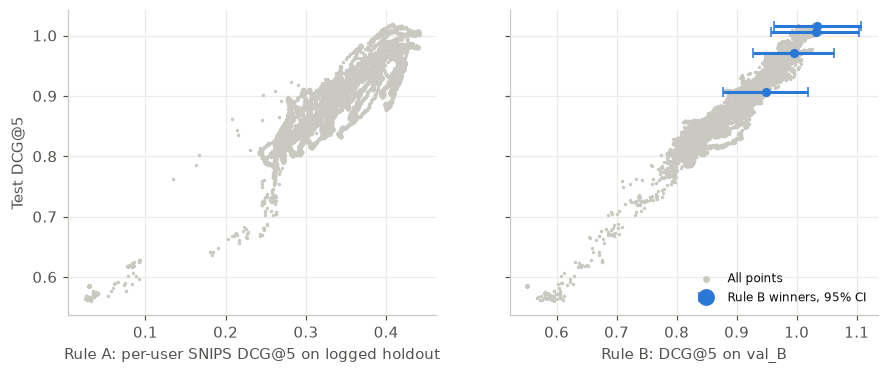

| family   |   val_B DCG@5 |   95% CI low |   95% CI high |   test DCG@5 |
|:---------|--------------:|-------------:|--------------:|-------------:|
| Naive MF |        0.9491 |       0.8777 |        1.0186 |       0.9063 |
| WMF      |        1.0342 |       0.9623 |        1.1076 |       1.0165 |
| SCAR     |        1.0326 |       0.9576 |        1.1038 |       1.0052 |
| Rel-MF   |        0.9948 |       0.9271 |        1.0623 |       0.9716 |
| rule   | reads          | picks                             |   step |   test DCG@5 |   rare-credit |   regret |   Rel-MF only: regret |
|:-------|:---------------|:----------------------------------|-------:|-------------:|--------------:|---------:|----------------------:|
| A0     | logged holdout | WMF (c′=100, λ̃=1)                 |   1110 |       1.0042 |        0.4700 |   0.0145 |                0.0051 |
| A      | logged holdout | WMF (c′=100, λ̃=1)                 |   1170 |       1.0051 |        0.4698 |   0.0135 |                0

| pair                  | seeds   |   val_B difference |   95% CI low |   95% CI high |   test difference |
|:----------------------|:--------|-------------------:|-------------:|--------------:|------------------:|
| WMF - SCAR            | 3       |            +0.0015 |      -0.0272 |       +0.0322 |           +0.0113 |
| WMF - SCAR            | 42 only |            -0.0031 |      -0.0320 |       +0.0267 |           +0.0130 |
| WMF - Rel-MF balanced | 3       |            -0.0028 |      -0.0287 |       +0.0236 |           +0.0112 |
| WMF - Rel-MF balanced | 42 only |            -0.0002 |      -0.0270 |       +0.0276 |           +0.0122 |
| WMF - Rel-MF          | 3       |            +0.0393 |      +0.0055 |       +0.0747 |           +0.0449 |
| WMF - Rel-MF          | 42 only |            +0.0306 |      -0.0083 |       +0.0701 |           +0.0430 |


|                 |   B minus A |   95% CI low |   95% CI high |
|:----------------|------------:|-------------:|--------------:|
| Naive MF        |     +0.0214 |      +0.0084 |       +0.0335 |
| WMF             |     +0.0135 |      +0.0040 |       +0.0220 |
| SCAR            |     +0.0002 |      -0.0020 |       +0.0024 |
| Rel-MF          |     -0.0016 |      -0.0107 |       +0.0074 |
| Rel-MF + nnPU   |     +0.0188 |      +0.0077 |       +0.0289 |
| Rel-MF balanced |     +0.0172 |      +0.0058 |       +0.0286 |
| BPR-MF          |     +0.0041 |      -0.0019 |       +0.0106 |


7922

In [4]:
L = d.val_b
ev = L.R.sum(1) > 0
idx = boot_idx(ev.sum())
fams = ["naive", "wmf", "scar", "relmf"]
pts = G[G.family.isin(fams)]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
for ax, col, label in ((axes[0], RULES["A"], "Rule A: per-user SNIPS DCG@5 on logged holdout"), (axes[1], RULES["B"], "Rule B: DCG@5 on val_B")):
    ax.scatter(pts[col], pts.test_dcg5, s=5, color=GRAY, linewidths=0, rasterized=True, label="All points")
    ax.set_xlabel(label)
axes[0].set_ylabel("Test DCG@5")
xs, los, his, ys = [], [], [], []
for f in fams:
    per_seed = [dcg(orders(v[L.row][ev], L.M[ev]), L.R[ev], 5) for v in score_vectors(scores, f, "B").values()]
    v = np.mean(per_seed, axis=0)
    lo, hi = np.percentile(v[idx].mean(1), [2.5, 97.5])
    t = d.test
    keep = t.R.sum(1) > 0
    y = np.mean([dcg(orders(s[t.row][keep], t.M[keep]), t.R[keep], 5).mean() for s in score_vectors(scores, f, "B").values()])
    xs.append(v.mean()); los.append(v.mean() - lo); his.append(hi - v.mean()); ys.append(y)
axes[1].errorbar(xs, ys, xerr=[los, his], fmt="o", color=BLUE, markersize=5, capsize=3, label="Rule B winners, 95% CI")
axes[1].legend(fontsize=8, loc="lower right", markerscale=2)
plt.savefig(RESULTS / "03_val_vs_test.png")
plt.show()

winners = pd.DataFrame({"family": [LABELS[f].split(" (")[0] for f in fams], "val_B DCG@5": xs, "95% CI low": [x - a for x, a in zip(xs, los)],
                        "95% CI high": [x + b for x, b in zip(xs, his)], "test DCG@5": ys})
print(winners.to_markdown(index=False, floatfmt=".4f"))
sizes = {"B": int(ev.sum())} | {k: int(v.sum()) for k, v in d.slices.items()}
reads = [f"{sizes[r]} users" if r in sizes else "test set" if r == "oracle" else "logged holdout" for r in all_pool["rule"]]
summary = all_pool.assign(reads=reads, **{"Rel-MF only: regret": relmf_pool.regret})[["rule", "reads", "picks", "step", "test DCG@5", "rare-credit", "regret", "Rel-MF only: regret"]]
print(summary.to_markdown(index=False, floatfmt=".4f"))



def rule_b_dcg(f, L_, keep_):
    """Per-user DCG@5 of a family's rule B fits: seeds by users, seed 42 first."""
    return np.array([dcg(orders(v[L_.row][keep_], L_.M[keep_]), L_.R[keep_], 5) for v in score_vectors(scores, f, "B").values()])


t, keep = d.test, d.test.R.sum(1) > 0
rows = []
for a, b in (("wmf", "scar"), ("wmf", "balanced"), ("wmf", "relmf")):
    va, vb = rule_b_dcg(a, L, ev), rule_b_dcg(b, L, ev)
    ta, tb = rule_b_dcg(a, t, keep), rule_b_dcg(b, t, keep)
    for seeds, n in (("3", 3), ("42 only", 1)):
        diff, lo, hi = paired_ci(va[:n].mean(0), vb[:n].mean(0), idx)
        rows.append({"pair": f"{LABELS[a].split(' (')[0]} - {LABELS[b].split(' (')[0]}", "seeds": seeds, "val_B difference": diff,
                     "95% CI low": lo, "95% CI high": hi, "test difference": (ta[:n] - tb[:n]).mean()})
val_b_pairs = pd.DataFrame(rows)
print(val_b_pairs.to_markdown(index=False, floatfmt="+.4f"))

test_idx = boot_idx(keep.sum())


def seed_avg_dcg(f, rule):
    return np.mean([dcg(orders(x[t.row][keep], t.M[keep]), t.R[keep], 5) for x in score_vectors(scores, f, rule).values()], axis=0)


b_minus_a = pd.DataFrame({LABELS[f].split(" (")[0]: dict(zip(("B minus A", "95% CI low", "95% CI high"), paired_ci(seed_avg_dcg(f, "B"), seed_avg_dcg(f, "A"), test_idx))) for f in FAMS}).T
print(b_minus_a.to_markdown(floatfmt="+.4f"))

(RESULTS / "03_selection.md").write_text(
    "### Summary (seed 42; N users = users in the slice with a relevant item; BPR-MF's step is an epoch)\n\n" + summary.to_markdown(index=False, floatfmt=".4f")
    + "\n\n### Regret, all models in the pool (seed 42; BPR-MF's step is an epoch)\n\n" + all_pool.to_markdown(index=False, floatfmt=".4f")
    + "\n\n### Regret, Rel-MF only (η = 0.5, seed 42)\n\n" + relmf_pool.to_markdown(index=False, floatfmt=".4f")
    + "\n\n### Regret by family and rule, with the family's oracle (seed 42)\n\n" + by_family.to_markdown(floatfmt=".4f")
    + "\n\n### Spearman with test DCG@5 across (configuration, step)\n\n" + spear.to_markdown(floatfmt=".3f")
    + "\n\n### Family winners under rule B on val_B (3 seeds)\n\n" + winners.to_markdown(index=False, floatfmt=".4f")
    + "\n\n### Paired val_B differences between rule B winners, on fits selected on this slice\n\n" + val_b_pairs.to_markdown(index=False, floatfmt="+.4f")
    + "\n\n### Rule B minus rule A, test DCG@5 (3 seeds; configuration chosen at seed 42, step per seed)\n\n" + b_minus_a.to_markdown(floatfmt="+.4f") + "\n")

## 3. What the metric conventions do to the numbers

The paper's printed formulas, the official code and this project all report "DCG@5" and mean different things. The same two
models (naive MF and Rel-MF, rule A, averaged over 3 seeds) are read under each convention below. The rare
rows use the restricted reading, the official code's. A threshold of `n_i ≤ 500` marks most items as rare. The last row is the
evaluator at commit 25cfa65: all users, each user's own 10 items, relevance floor 0.01, the official discount. It reads every uniform-exposure
row, `val_B` users included, so it is valid for rule A only. The figure printed in the paper fits that evaluator: `(DCG@1 − MAP@1) / (1 − MAP@1)` reads
about 0.01 on its curves, and its Recall@5 of 0.50 to 0.58 exceeds the 0.45 that the printed formula allows over all users.

In [5]:
t = d.test
order = {f: [orders(s[t.row], t.M) for s in score_vectors(scores, f, "A").values()] for f in ("naive", "relmf")}
keep = t.R.sum(1) > 0
n_candidates = t.M.sum(1)


def reading(f, fn):
    return np.mean([fn(o) for o in order[f]], axis=0)


def conv(name, fn):
    a, b = reading("naive", fn), reading("relmf", fn)
    return {"convention": name, "DCG@5 naive": a[0], "DCG@5 Rel-MF": b[0], "DCG gain": b[0] / a[0] - 1,
            "Recall@5 naive": a[1], "Recall@5 Rel-MF": b[1], "Recall gain": b[1] / a[1] - 1,
            "AP@5 naive": a[2], "AP@5 Rel-MF": b[2], "AP gain": b[2] / a[2] - 1}


def main_conv(o):
    return dcg(o[keep], t.R[keep], 5).mean(), recall(o[keep], t.R[keep], 5).mean(), ap(o[keep], t.R[keep], 5).mean()


def official(o):
    return dcg(o[keep], t.R[keep], 5, official=True).mean(), recall(o[keep], t.R[keep], 5).mean(), ap(o[keep], t.R[keep], 5, normalise=False).mean()


def with_zero_users(o):
    # Zero-positive users count as 0 for DCG and AP; the official code gives them Recall@k = k / candidates.
    rc = np.where(keep, 0.0, 5 / n_candidates)
    rc[keep] = recall(o[keep], t.R[keep], 5)
    a = np.zeros(len(keep))
    a[keep] = ap(o[keep], t.R[keep], 5)
    return dcg(o, t.R, 5).mean(), rc.mean(), a.mean()


def rare_reading(is_rare):
    rel = t.R * is_rare[t.I]
    k = rel.sum(1) > 0
    mask = t.M & is_rare[t.I]

    def fn(o):
        # Candidates outside the rare set move behind every rare candidate; the order among rare ones is kept.
        hit = np.take_along_axis(mask, o, 1)
        o2 = np.take_along_axis(o, np.argsort(~hit, axis=1, kind="stable"), 1)
        return dcg(o2[k], rel[k], 5).mean(), recall(o2[k], rel[k], 5).mean(), ap(o2[k], rel[k], 5).mean()

    return fn


frac = (d.n_i <= 500).mean()


def official_eval(f):
    """(DCG@5, Recall@5, MAP@5) under the 25cfa65 evaluator, over all users, averaged over seeds."""
    out = []
    for x in score_vectors(scores, f, "A").values():
        per = []
        for L_ in (d.test, d.val_b):
            o = np.argsort(x[L_.row], axis=1, kind="stable")[:, ::-1]  # that evaluator's tie rule; Yahoo lists have no padding
            y = np.where(L_.M, 0.01 + 0.99 * L_.R, 0.0)
            top, hit = np.take_along_axis(y, o[:, :5], 1), np.take_along_axis(L_.R, o[:, :5], 1)
            per.append(np.c_[dcg(o, y, 5, official=True), top.sum(1) / y.sum(1), (hit * top.cumsum(1) / np.arange(1, 6)).sum(1)])
        out.append(np.concatenate(per).mean(0))
    return np.mean(out, axis=0)


off = {f: official_eval(f) for f in ("popularity", "naive", "ease", "bpr", "relmf", "balanced", "wmf", "scar")}
y_all = np.concatenate([np.where(L_.M, 0.01 + 0.99 * L_.R, 0.0) for L_ in (d.test, d.val_b)])
off_random = (discount(5, official=True).sum() * y_all.sum(1) / (y_all > 0).sum(1)).mean()
conv_table = pd.DataFrame([
    conv("This project", main_conv),
    conv("Official discount and unnormalised AP", official),
    conv("Zero-positive users in the mean", with_zero_users),
    conv("Rare restricted, bottom 50% of items", rare_reading(d.rare)),
    conv(f"Rare restricted, n_i ≤ 500 ({frac:.0%} of items)", rare_reading(d.n_i <= 500)),
    {"convention": "25cfa65 evaluator, re-implemented (all users, relevance floor 0.01)", "DCG@5 naive": off["naive"][0], "DCG@5 Rel-MF": off["relmf"][0], "DCG gain": off["relmf"][0] / off["naive"][0] - 1,
     "Recall@5 naive": off["naive"][1], "Recall@5 Rel-MF": off["relmf"][1], "Recall gain": off["relmf"][1] / off["naive"][1] - 1,
     "AP@5 naive": off["naive"][2], "AP@5 Rel-MF": off["relmf"][2], "AP gain": off["relmf"][2] / off["naive"][2] - 1},
]).set_index("convention")
conv_md = conv_table.to_markdown(floatfmt=".4f")
print(conv_md)
official_rows = {"Random (analytic)": off_random, **{LABELS[f].split(" (")[0]: v[0] for f, v in off.items()},
                 "Paper, printed Figure 2, WMF (read off)": 0.364, "Paper, printed Figure 2, ExpoMF (read off)": 0.403, "Paper, printed Figure 2, Rel-MF (read off)": 0.485}
official_md = pd.Series(official_rows, name="DCG@5").to_frame().to_markdown(floatfmt=".4f")
print(official_md)
(RESULTS / "03_conventions.md").write_text(
    "### One pair of models, six conventions (rule A, 3 seeds)\n\n" + conv_md + "\n\n"
    "This project: the paper's DCG discount, standard AP, users with at least one relevant test item. "
    "Official discount: ranks 1 and 2 weigh the same. Zero-positive users count as 0 for DCG and AP and get the official Recall@5 of 5 / candidates. "
    "Gains are relative, Rel-MF over naive MF.\n\n"
    "### DCG@5 on a re-implementation of the 25cfa65 evaluator (rule A, 3 seeds; read-offs are from arXiv v3, p. 8, accurate to about 0.0005)\n\n" + official_md + "\n")

| convention                                                          |   DCG@5 naive |   DCG@5 Rel-MF |   DCG gain |   Recall@5 naive |   Recall@5 Rel-MF |   Recall gain |   AP@5 naive |   AP@5 Rel-MF |   AP gain |
|:--------------------------------------------------------------------|--------------:|---------------:|-----------:|-----------------:|------------------:|--------------:|-------------:|--------------:|----------:|
| This project                                                        |        0.8848 |         0.9732 |     0.0998 |           0.6979 |            0.7630 |        0.0933 |       0.4883 |        0.5515 |    0.1293 |
| Official discount and unnormalised AP                               |        1.0361 |         1.1380 |     0.0983 |           0.6979 |            0.7630 |        0.0933 |       0.9423 |        1.0589 |    0.1238 |
| Zero-positive users in the mean                                     |        0.4000 |         0.4399 |     0.0998 |           0.5895 |

3008

## Takeaways

All on Yahoo! R3. Regret, picks, rare-credit and Spearman are seed 42; lines that say 3 seeds use the final fits, and so do the conventions. Test DCG@5 is close to 1 here, so a regret of 0.01 is about 1%.

* **A bucket of 540 users tunes 4 of 7 families better than logged data and ties in the other 3.** `val_B` has 540 users, 10% of the uniform-exposure users and 3.5% of all users, 239 of them with a positive. Over 3 seeds, rule B minus rule A has a CI above 0 on naive MF +0.0214 [+0.0084, +0.0335], WMF +0.0135 [+0.0040, +0.0220],
  nnPU +0.0188 [+0.0077, +0.0289] and balanced +0.0172 [+0.0058, +0.0286]. It covers 0 on SCAR +0.0002, BPR-MF +0.0041 and Rel-MF -0.0016. At seed 42 rule B has lower regret than rule A in 6 of 7 families: naive MF 0.0102 against 0.0218, WMF 0.0011 against 0.0135, Rel-MF 0.0108 against 0.0125, nnPU 0.0044 against 0.0293, balanced 0.0006 against 0.0191,
  BPR-MF 0.0163 against 0.0164, with SCAR at 0.0066 against 0.0061. Spearman with test DCG@5 is above rule A's in all four families checked (0.876 to 0.986 against 0.772 to 0.909). On Rel-MF A0 has the lowest regret (0.0051 against 0.0108 for B) and the highest Spearman (0.928 against 0.876). On BPR-MF A+ has the lowest regret (0.0101 against 0.0163).
* **Across all models A0, A and B tie,** at 0.0145, 0.0135 and 0.0141, and all three land on a constant-weight family. The slice cannot rank those close families: at seed 42, WMF minus SCAR on `val_B` is -0.0031 [-0.0320, +0.0267], while on test it is +0.0130. WMF minus Rel-MF, a wider gap, excludes 0 only on 3 seeds: +0.0393 [+0.0055, +0.0747], against
  +0.0306 [-0.0083, +0.0701] at seed 42. These are paired over the same 239 users, on fits selected on this slice.
* **Per-user SNIPS adds little over no correction.** A and A0 correlate at 0.824 to 0.984 across fits, and on Rel-MF A0 has the lower regret (0.0051 against 0.0125).
* **Pooled SNIPS selects badly.** A+ has regret 0.0575 across all models and the largest of A0, A, A+ and B in 5 of 7 families. Its pick has rare-credit 0.0044 above A's at seed 42, a sign that is not stable (+0.0005 and -0.0033 at seeds 43 and 44 with the same two configurations, step re-selected per seed).
* **Smaller slices are erratic.** The two 5% halves have regret 0.0418 and 0.0138 across all models, and 0.0526 and 0.0219 within Rel-MF. The four 2.5% quarters range from 0.0136 to 0.0453 and pick three different families. These slices do not give a minimum size. 239 users with a positive is the largest slice I have and there is only one of it, so they show that half of it is erratic here, not that 239 is enough.
* **Conventions move the numbers more than the models do.** The same Rel-MF fits (3 seeds) read DCG@5 0.9732, 1.1380, 0.4399 or 0.5438 depending on the discount, the relevance floor and who counts as a user. The rare reading's gain over naive MF is +4.2% with the bottom 50% of items and +10.3% with `n_i ≤ 500`, which is 96% of items and so close to the all-item reading. Absolute numbers compare only within one convention.
* **For a team:** the uniform slice is what an exploration bucket provides. SNIPS on logged data is what remains without one. The paper tunes with SNIPS because its logged validation data and its randomly selected test data have different item distributions (Sec. 6.1.1, 6.1.4); it does not discuss tuning on a uniform slice.